# Part A · Nine charts, rebuilt and taken apart

**Ali Afzal** · BSAI-7B-102 · Data Visualization · Week 4

Each case below follows the analyst's recipe exactly, checks the self-check number from the brief, and
then asks four questions: what does the chart invite me to conclude, what objection comes to mind first
(and why it doesn't hold), what is really producing the pattern, and what does the honest chart look like.

None of these charts is broken by a drawing decision. The fault in each one happens before anything is
drawn: a parse, a resample, a window or a denominator. So every mechanism below is proved with a number
computed from the file, not by pointing at the picture.

Every figure puts the published chart on the left (titled **AS PUBLISHED**) and my redesign on the right.

In [1]:
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import tslib
from vizlib import PALETTE, save_fig, style_defaults

DATA = Path("data")
CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)

style_defaults(dpi=100)
plt.rcParams["date.converter"] = "concise"   # short, non-overlapping date ticks
BLUE, ORANGE, GREEN = PALETTE["series"]
PINK = PALETTE["series_4th"]
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]
SOURCE = "Source: synthetic course data, CDB601220 Week 4."


def save(fig, name, note=""):
    save_fig(fig, CHARTS / name, note=f"{note}  {SOURCE}".strip())


def wrap(text, width=55):
    return textwrap.fill(text, width)


def published(ax, claim):
    ax.set_title(wrap(f"AS PUBLISHED: “{claim}”", 60), fontsize=10, color=SOFT)

---
## 1 · "Orders peak in Q1 and collapse every year — a clear annual cycle"

Recipe: sort the 24 rows by `month`, plot `orders` as a line with markers, y from zero.

In [2]:
c1 = pd.read_csv(DATA / "case01_orders_stringdate.csv")
pub1 = c1.sort_values("month").reset_index(drop=True)
step = pub1.orders.diff()

print(f"{len(pub1)} points")
print("drops:", step[step < 0].astype(int).tolist())
print("order the string sort produced:", pub1.month.tolist()[:6], "...")

24 points
drops: [-958, -978]
order the string sort produced: ['2024-1', '2024-10', '2024-11', '2024-12', '2024-2', '2024-3'] ...


**Self-check:** 24 points, and the two drops are −958 and −978, as the brief says.

**The conclusion it invites.** Orders build up from January, hit a peak, and crash every year.

**The decoy.** "Some months must be missing, or one month is a bad entry." Neither holds. There are 24
distinct months, two complete years with no gaps, and every value is between 4,200 and 6,405. Nothing is
missing and nothing is extreme.

In [3]:
c1["date"] = pd.to_datetime(c1.month, format="%Y-%m")
true1 = c1.sort_values("date").reset_index(drop=True)

moved = (pub1.month != true1.month).sum()
true_step = true1.orders.diff().dropna()
print(f"rows in the wrong position after the text sort: {moved} of {len(c1)}")
print(f"true month-on-month changes: {int((true_step > 0).sum())} rises, {int((true_step < 0).sum())} falls, "
      f"smallest rise +{int(true_step.min())}")

rows in the wrong position after the text sort: 22 of 24
true month-on-month changes: 23 rises, 0 falls, smallest rise +59


**The mechanism.** `month` is text written `YYYY-M` with no zero padding, so `sort_values` sorts it
alphabetically: `2024-1`, `2024-10`, `2024-11`, `2024-12`, `2024-2`, … October, November and December
land between January and February. That puts 22 of the 24 rows in the wrong place. The "Q1 peak" is
really the high Q4 values pulled in next to January, and the "collapse" is the jump back from December to
February. In true calendar order there are **23 rises and 0 falls**.

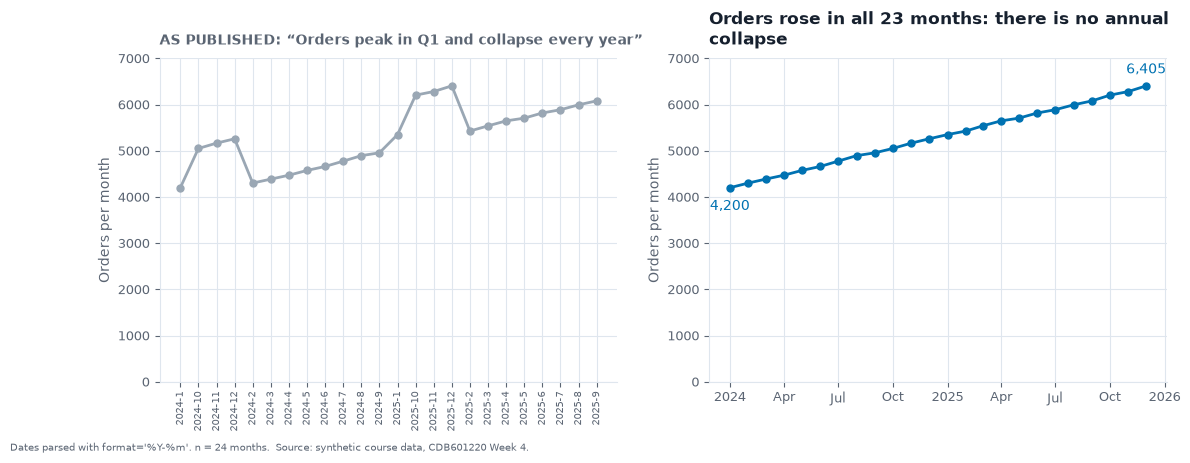

In [4]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.2))
a.plot(range(len(pub1)), pub1.orders, color=GREY, marker="o")
a.set_xticks(range(len(pub1)), pub1.month, rotation=90, fontsize=7)
a.set_ylim(0, 7000)
a.set_ylabel("Orders per month")
published(a, "Orders peak in Q1 and collapse every year")

b.plot(true1.date, true1.orders, color=BLUE, marker="o")
b.set_ylim(0, 7000)
b.set_ylabel("Orders per month")
b.annotate(f"{true1.orders.iloc[0]:,}", (true1.date.iloc[0], true1.orders.iloc[0]), xytext=(0, -16),
           textcoords="offset points", ha="center", color=BLUE)
b.annotate(f"{true1.orders.iloc[-1]:,}", (true1.date.iloc[-1], true1.orders.iloc[-1]), xytext=(0, 9),
           textcoords="offset points", ha="center", color=BLUE)
b.set_title(wrap("Orders rose in all 23 months: there is no annual collapse"))
save(fig, "a1_string_dates.png", "Dates parsed with format='%Y-%m'. n = 24 months.")

**The redesign.** The same line, on a real date axis (`format="%Y-%m"`). It's the plainest chart in this
notebook, and that's the point: the fix is the parse, not the chart type.

---
## 2 · "Sales grew steadily, 22%, across the quarter"

Recipe: plot `sales_pkr_k` against row number, add a least-squares trend line.

In [5]:
c2 = pd.read_csv(DATA / "case02_shop_closed.csv", parse_dates=["date"]).set_index("date").sales_pkr_k
first, last = c2.iloc[0], c2.iloc[-1]
print(f"{len(c2)} points, first {first}, last {last}, change {last / first - 1:+.0%}")

span = (c2.index.max() - c2.index.min()).days + 1
missing = pd.date_range(c2.index.min(), c2.index.max()).difference(c2.index)
print(f"rows: {len(c2)}, calendar days in the span: {span}, never recorded: {len(missing)}")
print(f"missing run: {missing.min().date()} to {missing.max().date()}; "
      f"weekdays hit: {pd.Series(missing.day_name()).value_counts().to_dict()}")

69 points, first 207, last 253, change +22%
rows: 69, calendar days in the span: 90, never recorded: 21
missing run: 2025-02-03 to 2025-02-23; weekdays hit: {'Monday': 3, 'Tuesday': 3, 'Wednesday': 3, 'Thursday': 3, 'Friday': 3, 'Saturday': 3, 'Sunday': 3}


**Self-check:** 69 points, first 207, last 253, +22%. ✓

**The conclusion it invites.** Sales rose a little every day for three months.

**The decoy.** "The shop is closed at weekends, so those days are missing, and that's harmless." That's
what `len(df)` against the date span first suggests: 69 rows in 90 days. But the 21 missing days are not
scattered weekends. Every weekday is missing exactly three times, and the 21 days are consecutive. The shop
was shut for **three weeks, 3 to 23 February**.

In [6]:
before, after = c2[:"2025-02-02"], c2["2025-02-24":]


def slope_per_day(s):
    return np.polyfit((s.index - s.index[0]).days, s.values, 1)[0]


print(f"before the closure: {len(before)} days, mean {before.mean():.0f}, slope {slope_per_day(before):+.2f} per day")
print(f"after reopening:    {len(after)} days, mean {after.mean():.0f}, slope {slope_per_day(after):+.2f} per day")
print(f"last day before {before.iloc[-1]} -> first day after {after.iloc[0]} "
      f"({after.iloc[0] / before.iloc[-1] - 1:+.0%})")
row_slope = np.polyfit(range(len(c2)), c2.values, 1)[0]
print(f"trend slope per ROW {row_slope:.2f}  vs per calendar DAY {slope_per_day(c2):.2f}")

before the closure: 33 days, mean 196, slope -0.16 per day
after reopening:    36 days, mean 252, slope +0.23 per day
last day before 198 -> first day after 262 (+32%)
trend slope per ROW 1.23  vs per calendar DAY 0.90


**The mechanism.** Plotting against row number deletes the 21 days the shop was closed, so 2 February and
24 February sit one step apart. That welds two flat stretches into one ramp. January was flat, even
drifting down (−0.16 per day around a mean of 196). Then the shop reopened **32% higher** (198 → 262) and
stayed around 252. The "steady growth" is a step change across a closure the x axis can't show. And the
trend line's slope is overstated by a third (1.23 per row against 0.90 per calendar day), because 90 days
of change are squeezed into 69 steps.

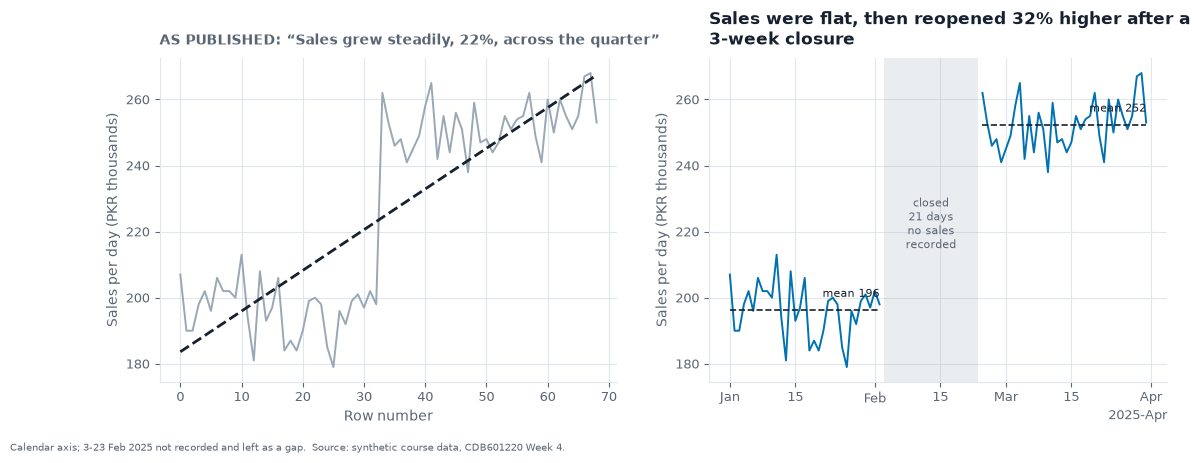

In [7]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.2))
a.plot(range(len(c2)), c2.values, color=GREY, lw=1.4)
a.plot(range(len(c2)), np.polyval(np.polyfit(range(len(c2)), c2.values, 1), range(len(c2))), color=INK, ls="--")
a.set_xlabel("Row number")
a.set_ylabel("Sales per day (PKR thousands)")
published(a, "Sales grew steadily, 22%, across the quarter")

full = tslib.reindex_full(c2, "D")
b.plot(full.index, full.values, color=BLUE, lw=1.4)
for seg in (before, after):
    b.hlines(seg.mean(), seg.index[0], seg.index[-1], color=INK, lw=1.2, ls="--")
    b.text(seg.index[-1], seg.mean() + 4, f"mean {seg.mean():.0f}", ha="right", fontsize=8, color=INK)
b.axvspan(missing.min(), missing.max(), color=GREY, alpha=0.2, lw=0)
b.text(missing.min() + (missing.max() - missing.min()) / 2, 215, "closed\n21 days\nno sales\nrecorded",
       ha="center", fontsize=8, color=SOFT)
b.set_ylabel("Sales per day (PKR thousands)")
b.set_title(wrap("Sales were flat, then reopened 32% higher after a 3-week closure"))
save(fig, "a2_row_number_axis.png", "Calendar axis; 3-23 Feb 2025 not recorded and left as a gap.")

**The redesign.** The same line on a calendar axis. The closure is left as a visible gap, not bridged, and
each segment has its own mean. Leadership should be asking what changed during the closure: a refit, new
stock, a price change. "Steady growth" sends them looking in the wrong place.

---
## 3 · "Peak load jumped 43% overnight on 1 July"

Recipe: resample `concurrent_users` to daily with `.sum()`, plot as a line from zero.

In [8]:
c3 = pd.read_csv(DATA / "case03_bandwidth_levels.csv", parse_dates=["ts"]).set_index("ts")
daily_sum = c3.concurrent_users.resample("D").sum()
jun, jul = daily_sum["2025-06"].mean(), daily_sum["2025-07"].mean()
print(f"June daily mean {jun:,.0f}, July {jul:,.0f}, step {jul / jun - 1:+.0%}")

audit3 = tslib.audit_index(c3, "h")
print(f"audit: {audit3['n_rows']} rows, {audit3['n_missing']} hours never recorded, "
      f"{audit3['n_duplicated']} duplicates")

June daily mean 8,782, July 12,543, step +43%
audit: 1237 rows, 227 hours never recorded, 0 duplicates


**Self-check:** June about 8,800, July about 12,500, +43%. ✓

**The conclusion it invites.** Something happened on 1 July: a launch, a campaign, a new region.

**The decoy.** "July has 31 days and June has 30." That can't matter, because both numbers are already
per-day means. A second decoy is "load really does rise in summer". The level per recorded hour says no
(below).

In [9]:
hours = c3.concurrent_users.resample("D").count()
lost = pd.date_range("2025-06-01", "2025-07-31 23:00", freq="h").difference(c3.index)
per_hour = c3.concurrent_users.resample("D").mean()
peak = c3.concurrent_users.resample("D").max()

print(f"hours recorded per day: June {hours['2025-06'].mean():.1f}, July {hours['2025-07'].mean():.1f}")
print(f"missing hours by month: {pd.Series(lost.month).value_counts().to_dict()}; "
      f"busiest missing hours of day: {pd.Series(lost.hour).value_counts().head(4).to_dict()}")
print(f"ratio of hours recorded, July/June: {hours['2025-07'].mean() / hours['2025-06'].mean():.2f}")
print(f"daily MEAN of the level: June {per_hour['2025-06'].mean():.0f}, July {per_hour['2025-07'].mean():.0f} "
      f"({per_hour['2025-07'].mean() / per_hour['2025-06'].mean() - 1:+.1%})")
print(f"daily PEAK of the level: June {peak['2025-06'].mean():.0f}, July {peak['2025-07'].mean():.0f} "
      f"({peak['2025-07'].mean() / peak['2025-06'].mean() - 1:+.1%})")

hours recorded per day: June 16.4, July 24.0
missing hours by month: {6: 227}; busiest missing hours of day: {13: 15, 14: 15, 10: 15, 8: 13}
ratio of hours recorded, July/June: 1.46
daily MEAN of the level: June 536, July 523 (-2.5%)
daily PEAK of the level: June 779, July 808 (+3.7%)


**The mechanism.** Two faults stack on top of each other.

1. `concurrent_users` is a **level**, a head-count at one instant. Adding 24 snapshots doesn't count
   anything real. It's "user-hours", and it grows with the number of snapshots, not the number of users.
2. June is missing **227 hours**, an average of 16.4 recorded hours a day against 24.0 in July, and the
   gaps fall mostly in the busy middle of the day. So June's sums add up fewer snapshots.

24.0 / 16.4 = 1.46, which is the whole of the "+43%". The level itself didn't move: the daily mean fell
2.5% (536 → 523) and the daily peak rose 3.7% (779 → 808). The logger was fixed on 1 July. The load
wasn't.

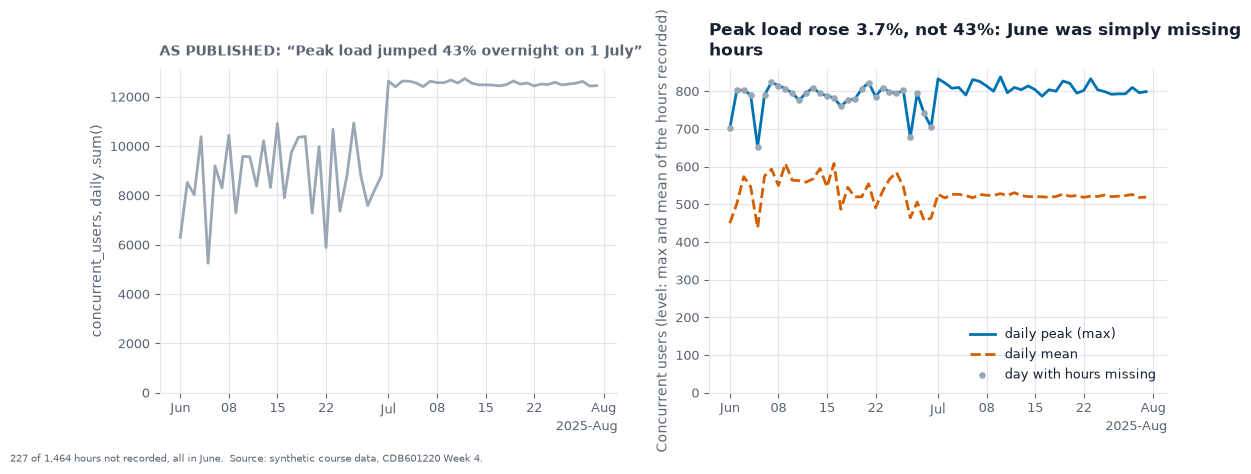

In [10]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.2))
a.plot(daily_sum.index, daily_sum.values, color=GREY)
a.set_ylim(0)
a.set_ylabel("concurrent_users, daily .sum()")
published(a, "Peak load jumped 43% overnight on 1 July")

short = hours < 24
b.plot(peak.index, peak.values, color=BLUE, label="daily peak (max)")
b.plot(per_hour.index, per_hour.values, color=ORANGE, ls="--", label="daily mean")
b.scatter(peak.index[short], peak.values[short], s=14, color=GREY, zorder=3, label="day with hours missing")
b.set_ylim(0)
b.set_ylabel("Concurrent users (level: max and mean of the hours recorded)")
b.legend(loc="lower right")
b.set_title(wrap("Peak load rose 3.7%, not 43%: June was simply missing hours"))
save(fig, "a3_level_summed.png", f"{len(lost)} of 1,464 hours not recorded, all in June.")

**The redesign.** A level is resampled with `max()` when the question is peak load, or `mean()` when it's
typical load, never `sum()`. The days with missing hours are marked so the reader can see June was the
patchy month. (`bytes_served` is a real flow, and its daily sum *also* shows a fake +43%, because a sum of
a flow still needs every hour present. Its per-hour mean is flat too.)

---
## 4 · "The new checkout flow started working on 7 September"

Recipe: raw `conversion_pct` in grey, a 31-day **trailing** mean on top, turning point read off the smoothed
line.

In [11]:
c4 = pd.read_csv(DATA / "case04_intervention_lag.csv", parse_dates=["date"]).set_index("date").conversion_pct
trail = c4.rolling(31).mean()
print("trailing 31-day mean bottoms out on", trail.idxmin().date())
print(tslib.audit_index(c4, "D"))

trailing 31-day mean bottoms out on 2025-09-07
{'dtype_ok': True, 'monotonic': True, 'n_rows': 214, 'n_duplicated': 0, 'n_missing': 0, 'missing_dates': [], 'span': ('2025-05-01 00:00:00', '2025-11-30 00:00:00'), 'partial_tail': False, 'tail_period': '2025-11', 'tail_count': 30}


**Self-check:** the trailing mean bottoms out on 2025-09-07. ✓

**The conclusion it invites.** Conversion turned upward on 7 September, so the flow released then works.

**The decoy.** "The upturn is just noise." It isn't. The index is clean (214 days, no gaps, no duplicates),
and the turn shows up under any smoother. Fitting a broken line (two straight segments) to the raw data
finds a real change of slope. The turn is real. Its *date* is wrong.

In [12]:
lag = tslib.lag_at_turn(c4, 31, how="min")
centred = c4.rolling(31, center=True).mean()

x = np.arange(len(c4))
best = min(range(20, len(c4) - 20), key=lambda k: np.linalg.lstsq(
    np.column_stack([np.ones_like(x), x, np.maximum(0, x - k)]), c4.values, rcond=None)[1][0])
print(f"trailing turn {lag['trailing_turn'].date()}, centred turn {lag['centred_turn'].date()}, "
      f"lag {lag['lag_periods']} days (half-window {lag['half_window']})")
print(f"broken-line fit on the RAW data puts the change at {c4.index[best].date()}")

trailing turn 2025-09-07, centred turn 2025-08-23, lag 15 days (half-window 15)
broken-line fit on the RAW data puts the change at 2025-08-28


**The mechanism.** A trailing mean dated *t* averages days *t−30* to *t*, so it describes a point about 15
days earlier than its label. When the raw series turns, the trailing mean keeps falling until enough
post-turn days fill the window. `lag_at_turn` measures the delay: the centred mean bottoms on **23 August**
and the trailing mean on **7 September**, a lag of **15 days**, exactly half the 31-day window. A
broken-line fit on the raw data, which uses no smoothing at all, puts the change at 28 August. Conversion
was improving two weeks before the date in the claim. If the flow went live on 7 September, it can't be
the cause.

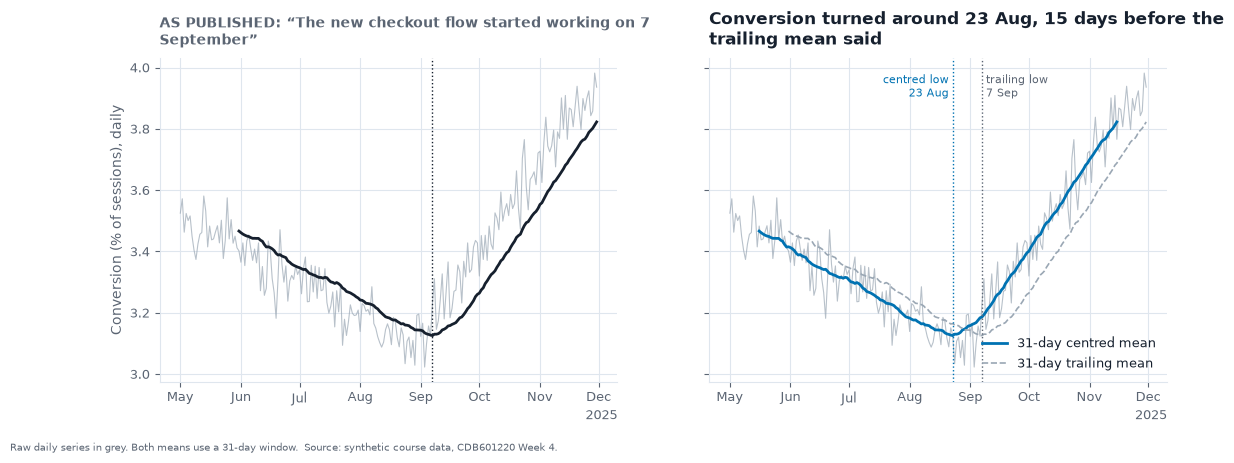

In [13]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax in (a, b):
    ax.plot(c4.index, c4.values, color=GREY, lw=0.8, alpha=0.7)
a.plot(trail.index, trail.values, color=INK)
a.axvline(trail.idxmin(), color=INK, ls=":", lw=1)
a.set_ylabel("Conversion (% of sessions), daily")
published(a, "The new checkout flow started working on 7 September")

b.plot(centred.index, centred.values, color=BLUE, label="31-day centred mean")
b.plot(trail.index, trail.values, color=GREY, ls="--", lw=1.2, label="31-day trailing mean")
for d, col, txt, side in [(lag["centred_turn"], BLUE, "centred low \n23 Aug ", "right"),
                          (lag["trailing_turn"], SOFT, " trailing low\n 7 Sep", "left")]:
    b.axvline(d, color=col, ls=":", lw=1)
    b.text(d, c4.max(), txt, ha=side, va="top", fontsize=8, color=col)
b.legend(loc="lower right")
b.set_title(wrap("Conversion turned around 23 Aug, 15 days before the trailing mean said"))
save(fig, "a4_trailing_lag.png", "Raw daily series in grey. Both means use a 31-day window.")

**The redesign.** The same chart with a **centred** 31-day mean, which puts each average at the middle of
the days it covers, so the turn lands where it happened. A centred mean can't be computed for the last 15
days, so a live dashboard can't use one. There, the honest version keeps the trailing mean and says so in
the caption: *"31-day trailing mean; turns appear about 15 days late."*

---
## 5 · "Revenue has fallen for six straight months"

Recipe: May to November 2025 only, a line with markers, y-axis from zero.

In [14]:
c5 = pd.read_csv(DATA / "case05_revenue_window.csv")
c5["date"] = pd.to_datetime(c5.month, format="%Y-%m")
s5 = c5.set_index("date").revenue_pkr_m
win = s5["2025-05":"2025-11"]
print(f"{len(win)} points, {win.iloc[0]} -> {win.iloc[-1]}, {win.iloc[-1] / win.iloc[0] - 1:+.1%}")
print(tslib.audit_index(s5, "MS"))

7 points, 158.8 -> 92.2, -41.9%
{'dtype_ok': True, 'monotonic': True, 'n_rows': 36, 'n_duplicated': 0, 'n_missing': 0, 'missing_dates': [], 'span': ('2023-01-01 00:00:00', '2025-12-01 00:00:00'), 'partial_tail': False, 'tail_period': '2025', 'tail_count': 12}


**Self-check:** 7 points, 158.8 down to 92.2, −41.9%. ✓

**The conclusion it invites.** The business is in steady decline.

**The decoy.** "The y axis is truncated" is wrong, because it starts at zero. "Seven points is too small a
sample" is wrong too. All seven are complete months, the file has 36 of them with no gaps, and the fall
isn't noise: every month really is lower than the one before.

In [15]:
by_year = s5.groupby(s5.index.year)
for y in (2023, 2024, 2025):
    may, nov = s5[f"{y}-05"].iloc[0], s5[f"{y}-11"].iloc[0]
    print(f"{y}: May {may:6.1f} -> Nov {nov:5.1f}  ({nov / may - 1:+.1%}); peak month {s5[str(y)].idxmax():%b}")
yoy = (s5 / s5.shift(12) - 1).dropna()
print(f"year-on-year growth, every month of 2024-25: min {yoy.min():+.1%}, max {yoy.max():+.1%}, "
      f"negative in {(yoy < 0).sum()} of {len(yoy)}")
print(f"annual totals: {by_year.sum().round(1).to_dict()}  (2025 vs 2024: {by_year.sum()[2025] / by_year.sum()[2024] - 1:+.1%})")

2023: May  131.1 -> Nov  75.5  (-42.4%); peak month Jun
2024: May  147.5 -> Nov  84.4  (-42.8%); peak month May
2025: May  158.8 -> Nov  92.2  (-41.9%); peak month May
year-on-year growth, every month of 2024-25: min +4.9%, max +13.3%, negative in 0 of 24
annual totals: {2023: 1254.7, 2024: 1361.9, 2025: 1496.3}  (2025 vs 2024: +9.9%)


**The mechanism.** The window starts on the seasonal peak and ends near the trough. May is the highest
month in 2024 and 2025 (in 2023 June beat it by 1.9), and the May → November fall is −42.4% in 2023, −42.8% in 2024 and
−41.9% in 2025: the same shape each time. Against the same month a year earlier, revenue grew in **all 24**
months, by between +4.9% and +13.3%, and 2025 as a whole is up 9.9% on 2024. The chart is a faithful
picture of a normal season, framed as a collapse.

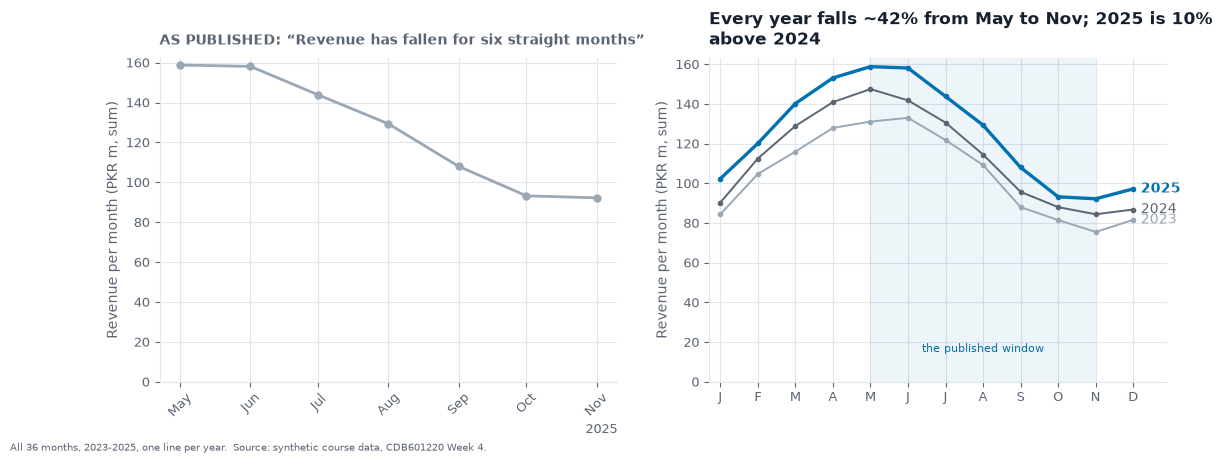

In [16]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.2))
a.plot(win.index, win.values, color=GREY, marker="o")
a.set_ylim(0)
a.set_ylabel("Revenue per month (PKR m, sum)")
a.tick_params(axis="x", labelrotation=45)
published(a, "Revenue has fallen for six straight months")

piv = s5.groupby([s5.index.month, s5.index.year]).sum().unstack()
for yr, col, lw in [(2023, GREY, 1.4), (2024, SOFT, 1.4), (2025, BLUE, 2.4)]:
    b.plot(piv.index, piv[yr], color=col, lw=lw, marker="o", ms=3)
    b.text(12.2, piv[yr].iloc[-1], str(yr), va="center", color=col, fontweight="bold" if yr == 2025 else "normal")
b.axvspan(5, 11, color=BLUE, alpha=0.07, lw=0)
b.text(8, 15, "the published window", ha="center", fontsize=8, color=BLUE)
b.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
b.set_xlim(0.7, 12.9)
b.set_ylim(0)
b.set_ylabel("Revenue per month (PKR m, sum)")
b.set_title(wrap("Every year falls ~42% from May to Nov; 2025 is 10% above 2024"))
save(fig, "a5_seasonal_window.png", "All 36 months, 2023-2025, one line per year.")

**The redesign.** The same line chart, still from zero, with the two earlier years laid beside it so the
window has something to be compared with. This is one of the two "incomplete, not wrong" cases. The seven
points are right, and what was missing was the context.

---
## 6 · "Orders collapsed in October"

Recipe: resample `orders` to monthly totals with `.sum()`, bars from zero.

In [17]:
c6 = pd.read_csv(DATA / "case06_monthly_partial.csv", parse_dates=["date"]).set_index("date").orders
monthly = c6.resample("MS").agg(["sum", "count", "mean"])
monthly["days_in_month"] = monthly.index.days_in_month
print(monthly.tail(3))
print(f"October = {monthly['sum'].iloc[-1] / monthly['sum'].iloc[-2]:.0%} of September")
audit6 = tslib.audit_index(c6, "D")
print({k: audit6[k] for k in ("n_missing", "partial_tail", "tail_period", "tail_count", "span")})

              sum  count        mean  days_in_month
date                                               
2025-08-01  11042     31  356.193548             31
2025-09-01  10805     30  360.166667             30
2025-10-01   4041     11  367.363636             31
October = 37% of September
{'n_missing': 0, 'partial_tail': True, 'tail_period': '2025-10', 'tail_count': 11, 'span': ('2025-01-01 00:00:00', '2025-10-11 00:00:00')}


**Self-check:** ten bars, September 10,805, October 4,041 (37%). ✓

**The conclusion it invites.** Something went badly wrong in October.

**The decoy.** "There was an outage in October, so days are missing." `audit_index` finds **no** missing
days, and every recorded October day is a normal one. The lowest October day (343) is higher than most of
September.

**The mechanism.** The extract stops on **11 October**. October's bar sums 11 days, and September's sums
30. `audit_index` flags it directly (`partial_tail=True`, 11 rows in the last period). Per day, October
averaged **367 orders**, the highest of the year and 2% above September's 360. The fall is 19 days that
hadn't happened yet when the file was pulled.

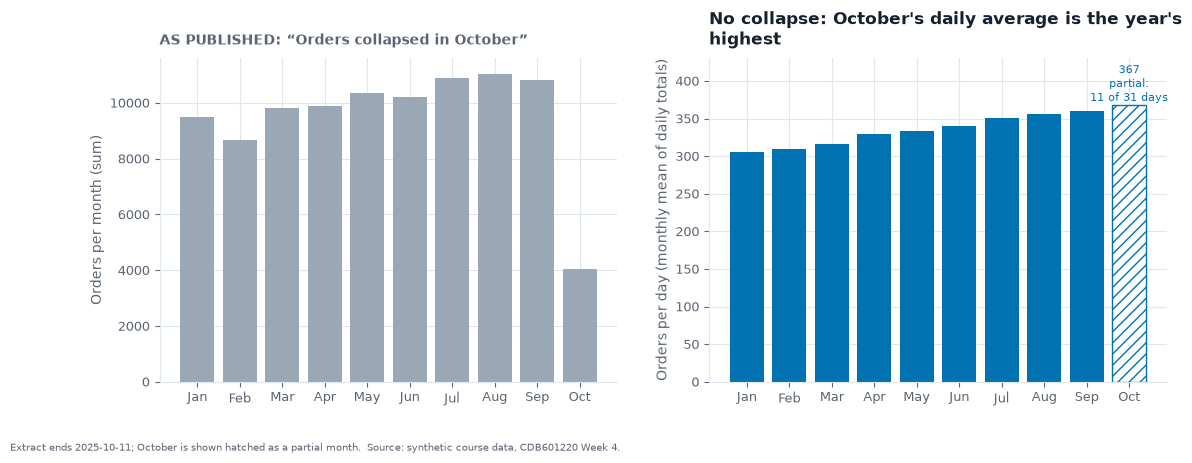

In [18]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.2))
lbl = monthly.index.strftime("%b")
a.bar(lbl, monthly["sum"], color=GREY)
a.set_ylabel("Orders per month (sum)")
published(a, "Orders collapsed in October")

partial = monthly["count"] < monthly["days_in_month"]
b.bar(lbl[~partial], monthly["mean"][~partial], color=BLUE)
b.bar(lbl[partial], monthly["mean"][partial], color="white", edgecolor=BLUE, hatch="///")
b.text(len(lbl) - 1, monthly["mean"].iloc[-1] + 6, f"{monthly['mean'].iloc[-1]:.0f}\npartial:\n11 of 31 days",
       ha="center", fontsize=8, color=BLUE)
b.set_ylim(0, 430)
b.set_ylabel("Orders per day (monthly mean of daily totals)")
b.set_title(wrap("No collapse: October's daily average is the year's highest"))
save(fig, "a6_partial_month.png", "Extract ends 2025-10-11; October is shown hatched as a partial month.")

**The redesign.** The same bars from zero, but each one is the **daily average**, which is fair to months of
any length, and the partial month is hatched and labelled. If leadership insists on monthly totals, the
alternative is to drop October until it's complete, and say so.

---
## 7 · "Product D has been erratic since mid-2024"

Recipe: a stacked area chart of the four products in column order, `product_a` at the bottom.

In [19]:
c7 = pd.read_csv(DATA / "case07_stacked_products.csv")
c7["date"] = pd.to_datetime(c7.month, format="%Y-%m")
c7 = c7.set_index("date").drop(columns="month")
total = c7.sum(axis=1)
print(f"total envelope: {total.min():.1f} to {total.max():.1f}")

total envelope: 548.3 to 708.7


**Self-check:** the envelope runs from 548 to 709. ✓

**The conclusion it invites.** The top band, product D, wobbles all over the place.

**The decoy.** "The stack is illegal because the parts overlap." It isn't. The data dictionary says the
four lines are exclusive and exhaustive, and the totals are plausible month to month. Stacking them is
*legal*. It just answers a different question from the one in the claim.

In [20]:
spread = pd.DataFrame({
    "sd": c7.std(),
    "cv_pct": c7.std() / c7.mean() * 100,
    "sd_of_monthly_change": c7.diff().std(),
}).round(1)
print(spread)
below_d = c7[["product_a", "product_b", "product_c"]].sum(axis=1)
print(f"SD of D's baseline (a+b+c): {below_d.std():.1f}   SD of D itself: {c7.product_d.std():.1f}")

             sd  cv_pct  sd_of_monthly_change
product_a  16.0     6.5                   4.7
product_b  35.6    23.4                  45.8
product_c   7.3     5.2                   6.4
product_d   3.6     3.5                   2.0
SD of D's baseline (a+b+c): 39.3   SD of D itself: 3.6


**The mechanism.** In a stacked area, each band sits on top of everything below it, so its *edges* carry
the wobble of every lower layer. Product D's own values are the **steadiest of the four**: SD 3.6, a
coefficient of variation of 3.5%, and month-to-month changes with an SD of just 2.0. The erratic one is
**product B**, the second layer, with SD 35.6, CV 23% and month-to-month changes with an SD of 45.8. D's
baseline (a+b+c) has an SD of 39.3, so D's band swings by 39 because B swings, while D itself moves by
3.6. The column the recipe never isolates is `product_b`. If D did anything "since mid-2024", it's a slow,
steady rise from about 97 to about 105.

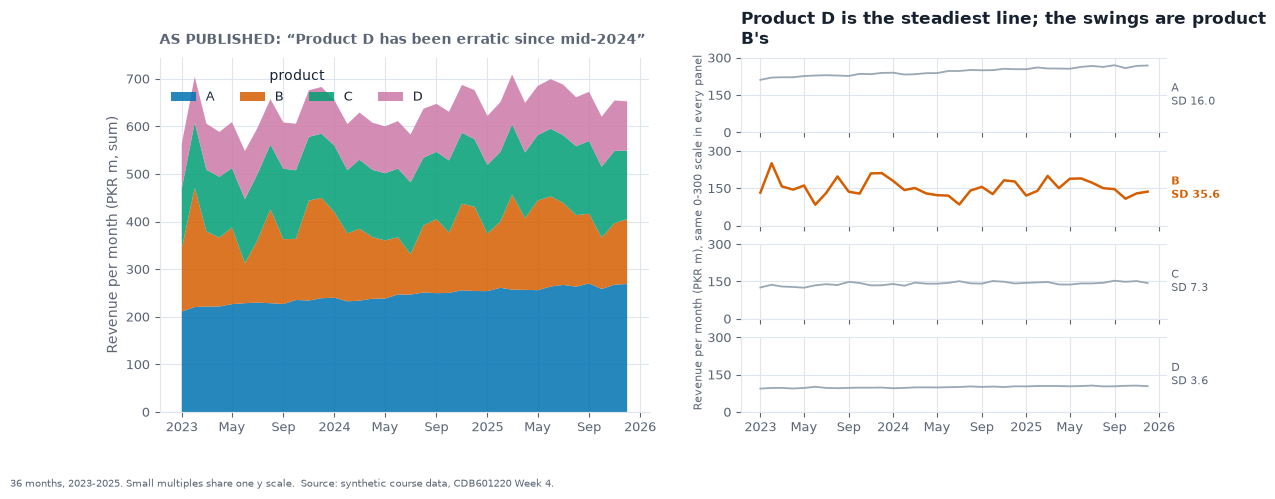

In [21]:
fig = plt.figure(figsize=(13, 4.6))
gs = fig.add_gridspec(4, 2, width_ratios=[1.15, 1], hspace=0.25)
a = fig.add_subplot(gs[:, 0])
cols = [BLUE, ORANGE, GREEN, PINK]
a.stackplot(c7.index, c7.T.values, colors=cols, labels=[c[-1].upper() for c in c7.columns], alpha=0.85)
a.legend(loc="upper left", ncol=4, title="product")
a.set_ylabel("Revenue per month (PKR m, sum)")
published(a, "Product D has been erratic since mid-2024")

for i, (col, c) in enumerate(zip(c7.columns, cols)):
    ax = fig.add_subplot(gs[i, 1])
    hot = col == "product_b"
    ax.plot(c7.index, c7[col], color=ORANGE if hot else GREY, lw=1.8 if hot else 1.3)
    ax.set_ylim(0, 300)
    ax.set_yticks([0, 150, 300])
    ax.text(1.01, 0.5, f"{col[-1].upper()}\nSD {c7[col].std():.1f}", transform=ax.transAxes, va="center",
            fontsize=8, color=ORANGE if hot else SOFT, fontweight="bold" if hot else "normal")
    if i < 3:
        ax.tick_params(labelbottom=False)
    if i == 0:
        ax.set_title(wrap("Product D is the steadiest line; the swings are product B's"))
fig.text(0.535, 0.5, "Revenue per month (PKR m), same 0-300 scale in every panel", rotation=90,
         va="center", fontsize=8, color=SOFT)
save(fig, "a7_stacked_baseline.png", "36 months, 2023-2025. Small multiples share one y scale.")

**The redesign.** Unstack it. Week 1 gave two ways out of spaghetti, and here I use small multiples: one
panel per product, each drawn from its own zero, **on a shared scale** so their wobbles can be compared
fairly. B's swings are obvious and D is nearly flat. If the total also matters, it goes in its own panel,
not as the roof of a stack.

---
## 8 · "Paid search drives 43% of our customers"

Recipe: count the `True` values in each `touch_*` column, divide by the number of customers, draw a
four-slice pie.

In [22]:
c8 = pd.read_csv(DATA / "case08_channel_attrib.csv")
flags = [c for c in c8.columns if c.startswith("touch_")]
ex = tslib.exclusivity_check(c8, flags)
print(ex)

{'n': 4000, 'shares_pct': {'touch_search': 42.62, 'touch_social': 32.3, 'touch_email': 27.48, 'touch_direct': 28.58}, 'sum_pct': 130.98, 'exclusive': False, 'n_multi': 1105, 'pct_multi': 27.62, 'n_zero': 0}


**Self-check:** search 42.6%, social 32.3%, email 27.5%, direct 28.6%. ✓ And they add up to **131.0%**.

**The conclusion it invites.** Search brings in 43% of customers, so it gets 43% of the budget.

**The decoy.** "Each percentage is miscounted." No, each one is exactly right *as a reach figure*: 1,705
of 4,000 customers really were touched by search at some point. The individual numbers are fine. Putting
them in a pie is what's wrong.

In [23]:
k = c8[flags].sum(axis=1)
sole = c8[k == 1][flags].sum() / len(c8) * 100
print("channels per customer:", k.value_counts().sort_index().to_dict())
print("customers touched by ONLY this channel (%):", sole.round(1).to_dict())
drawn = c8[flags].mean() / c8[flags].mean().sum() * 100
print("what ax.pie actually draws, after silently normalising to 100% (%):", drawn.round(1).to_dict())

channels per customer: {1: 2895, 2: 980, 3: 116, 4: 9}
customers touched by ONLY this channel (%): {'touch_search': 25.9, 'touch_social': 17.8, 'touch_email': 13.8, 'touch_direct': 14.8}
what ax.pie actually draws, after silently normalising to 100% (%): {'touch_search': 32.5, 'touch_social': 24.7, 'touch_email': 21.0, 'touch_direct': 21.8}


**The mechanism.** The parts aren't exclusive. **1,105 customers (27.6%) were touched by two or more
channels** (980 by two, 116 by three, 9 by all four), so they're counted in several slices and the slices
add up to 131%. A pie's whole has to be 100% of something, and here it isn't. Worse, `ax.pie` quietly
rescales any values that add up to more than 1, so the search slice is actually **drawn at 32.5% of the
circle**. Even the published picture doesn't show the 43% its caption claims. Search was the *only*
channel for 25.9% of customers.

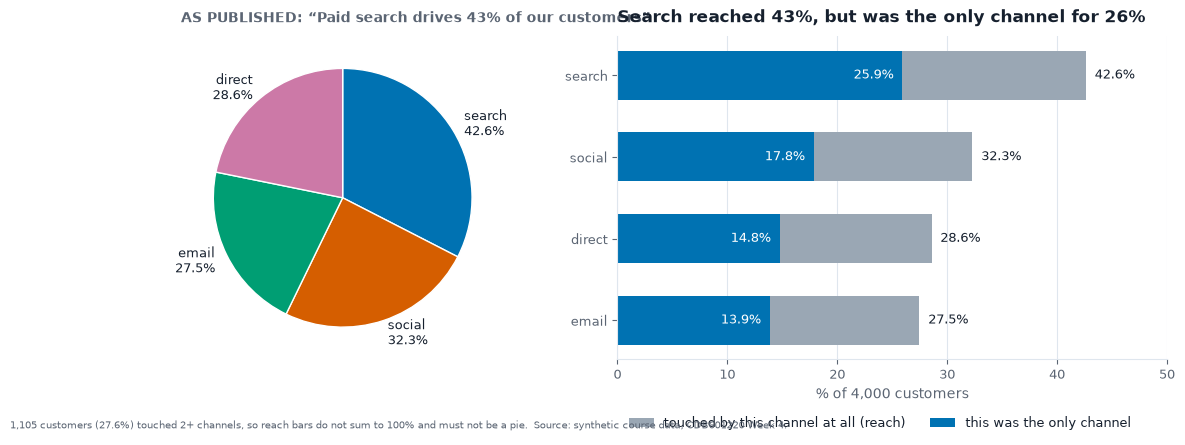

In [24]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[0.8, 1.2]))
names = [f.replace("touch_", "") for f in flags]
a.pie(c8[flags].mean(), labels=[f"{n}\n{v:.1f}%" for n, v in zip(names, ex["shares_pct"].values())],
      colors=[BLUE, ORANGE, GREEN, PINK], startangle=90, counterclock=False,
      wedgeprops=dict(edgecolor="white"))
published(a, "Paid search drives 43% of our customers")

order = np.argsort(c8[flags].mean().values)
reach = c8[flags].mean().values[order] * 100
only = sole.values[order]
y = np.arange(len(flags))
b.barh(y, reach, color=GREY, height=0.6, label="touched by this channel at all (reach)")
b.barh(y, only, color=BLUE, height=0.6, label="this was the only channel")
for yi, r, o in zip(y, reach, only):
    b.text(r + 0.8, yi, f"{r:.1f}%", va="center", fontsize=9)
    b.text(o - 0.8, yi, f"{o:.1f}%", va="center", ha="right", fontsize=9, color="white")
b.set_yticks(y, [names[i] for i in order])
b.set_xlim(0, 50)
b.set_xlabel("% of 4,000 customers")
b.legend(loc="upper left", bbox_to_anchor=(0, -0.14), ncol=2)
b.grid(axis="y", visible=False)
b.set_title(wrap("Search reached 43%, but was the only channel for 26%"))
save(fig, "a8_non_exclusive_pie.png",
     "1,105 customers (27.6%) touched 2+ channels, so reach bars do not sum to 100% and must not be a pie.")

**The redesign.** Bars, not slices, because bars don't promise to add up to anything. Each channel gets
its reach, and inside it the share of customers for whom it was the only channel. A note says plainly that
the bars overlap. If the question really is "how should credit be split?", that's an attribution model
(equal fractional credit gives search 33.9%), and it's a decision to state, not a pie to draw.

---
## 9 · "Premium is now 38% of revenue — a record"

Recipe: `premium / total` per quarter, plotted as a line from zero, last point annotated.

In [25]:
c9 = pd.read_csv(DATA / "case09_premium_share.csv")
c9["share"] = c9.premium_revenue_pkr_m / c9.total_revenue_pkr_m * 100
c9["other"] = c9.total_revenue_pkr_m - c9.premium_revenue_pkr_m
print(c9.round(1).to_string(index=False))

quarter  total_revenue_pkr_m  premium_revenue_pkr_m  share  other
 2024Q1               1000.0                  240.0   24.0  760.0
 2024Q2                940.0                  236.9   25.2  703.1
 2024Q3                870.0                  233.2   26.8  636.8
 2024Q4                800.0                  228.0   28.5  572.0
 2025Q1                745.0                  227.2   30.5  517.8
 2025Q2                700.0                  227.5   32.5  472.5
 2025Q3                650.0                  228.8   35.2  421.2
 2025Q4                600.0                  228.0   38.0  372.0


**Self-check:** 24.0% → 38.0%. ✓

**The conclusion it invites.** Premium is winning, so invest in premium.

**The decoy.** "The share is computed wrongly." It isn't. Premium is a genuine part of the total and the
division is right. 38% really is premium's share of 2025Q4 revenue. The number is true. The *story* about
it is the problem.

In [26]:
def pct(col):
    return c9[col].iloc[-1] / c9[col].iloc[0] - 1


print(f"2024Q1 -> 2025Q4: total {pct('total_revenue_pkr_m'):+.0%}, "
      f"premium {pct('premium_revenue_pkr_m'):+.0%}, everything else {pct('other'):+.0%}")

2024Q1 -> 2025Q4: total -40%, premium -5%, everything else -51%


**The mechanism.** A share has a numerator *and* a denominator, and here the denominator moved. Total
revenue fell **40%** (1,000 → 600). Premium revenue fell **5%** (240 → 228). Everything else fell **51%**
(760 → 372). Premium's share rose because the rest of the business shrank around it. "Record share" is
true, and on its own it describes a business that lost two-fifths of its revenue.

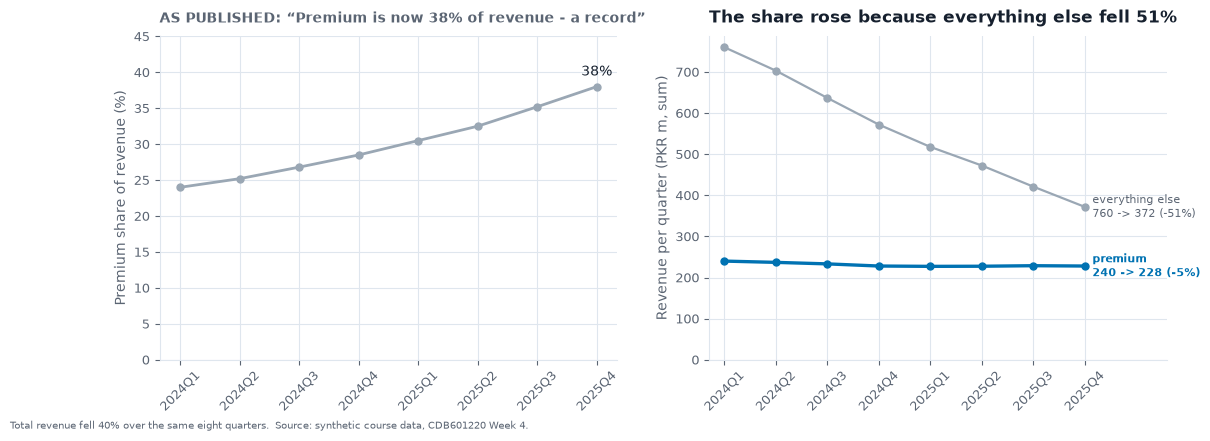

In [27]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.2))
q = c9.quarter
a.plot(q, c9.share, color=GREY, marker="o")
a.annotate(f"{c9.share.iloc[-1]:.0f}%", (7, c9.share.iloc[-1]), xytext=(0, 8), textcoords="offset points",
           ha="center")
a.set_ylim(0, 45)
a.set_ylabel("Premium share of revenue (%)")
published(a, "Premium is now 38% of revenue - a record")

b.plot(q, c9.other, color=GREY, marker="o", lw=1.6)
b.plot(q, c9.premium_revenue_pkr_m, color=BLUE, marker="o", lw=2.4)
b.text(7.15, c9.other.iloc[-1], f"everything else\n{c9.other.iloc[0]:.0f} -> {c9.other.iloc[-1]:.0f} (-51%)",
       va="center", fontsize=8, color=SOFT)
b.text(7.15, c9.premium_revenue_pkr_m.iloc[-1], f"premium\n240 -> 228 (-5%)", va="center", fontsize=8,
       color=BLUE, fontweight="bold")
b.set_xlim(-0.3, 8.6)
b.set_ylim(0)
b.set_ylabel("Revenue per quarter (PKR m, sum)")
b.set_title(wrap("The share rose because everything else fell 51%"))
for ax in (a, b):
    ax.tick_params(axis="x", labelrotation=45)
save(fig, "a9_share_of_falling_total.png", "Total revenue fell 40% over the same eight quarters.")

**The redesign.** Keep the share chart, because it's correct, and put the **absolute revenue** next to it,
from zero. This is the second "incomplete" case: the share line needed its denominator beside it. A reader
who sees both panels can't confuse "premium is growing" with "premium is shrinking more slowly than
everything else".

---
## Summary

| # | Claim | Mechanism | The number |
|---|---|---|---|
| 1 | Q1 peak, annual collapse | `YYYY-M` text sorted alphabetically | 22 of 24 rows misplaced; 23 rises, 0 falls in true order |
| 2 | Steady +22% | Row-number axis deletes a 21-day closure | Flat (−0.16/day), then a +32% step on reopening |
| 3 | +43% overnight | A level resampled with `sum()`, and June missing hours | 16.4 vs 24.0 hours/day; peak +3.7% |
| 4 | Worked from 7 Sep | Trailing mean lags the turn by half its window | 15-day lag; centred low 23 Aug |
| 5 | Six months of decline | Window starts at the seasonal peak | −42% May→Nov every year; YoY up in 24 of 24 months |
| 6 | October collapse | Incomplete final period | 11 of 31 days; daily mean 367, the year's high |
| 7 | D is erratic | Stacked baseline passes B's volatility upward | SD: D 3.6, B 35.6 |
| 8 | Search drives 43% | Non-exclusive parts in a pie | Sum 131%; 1,105 customers multi-touch |
| 9 | Record 38% share | Rising share of a falling total | Total −40%, premium −5%, rest −51% |

Cases 5 and 9 were **incomplete, not wrong**. Their redesign is the same chart with the missing context
beside it. In the other seven, the chart answered a question its data couldn't support.